

# Auspify Technologies - Data Science Internship
## Netflix Dataset - Tasks 1 to 6 (Single Notebook)

**Intern:** Akshat Kesharwani

| Task | Level | Topic |
|---|---|---|
| Task 1 | Easy | Data Cleaning & Preprocessing |
| Task 2 | Easy | Exploratory Data Analysis (EDA) |
| Task 3 | Medium | Recommendation System Analysis |
| Task 4 | Medium | Trend Prediction Analysis |
| Task 5 | Advanced | Machine Learning Classification Model |
| Task 6 | Advanced | Data Science Business Insights Dashboard |

**Dataset:** Netflix titles - 8,790 rows, 10 columns (show_id, type, title, director, country, date_added, release_year, rating, duration, listed_in)

#Auspify #AuspifyTechnologies #AuspifyInternship #AuspifyProjects

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
import warnings
warnings.filterwarnings("ignore")

df=pd.read_csv("/content/Dataset.csv")

print("rows and columns:", df.shape)
df.head()

rows and columns: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


# Task 1 (Easy) - Data Cleaning & Preprocessing
**Goal:** clean the raw Netflix data and make a clean dataset for the next tasks.

Steps: import data → find missing and duplicate records → fix nulls and formats → transform columns → save clean data.

## Step 1: Look at the raw data

In [3]:
df.info()
print()
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB

       release_year
count   8790.000000
mean    2014.183163
std        8.825466
min     1925.000000
25%     2013.000000
50%     2017.000000
75%     2019.000000
max     2021.000000


## Step 2: Missing and duplicate records

In [4]:
print("Normal null values:")
print(df.isnull().sum())
print()

# in this file missing values are written as the text "Not Given"
print("'Not Given' count in each column:")
for col in df.columns:
    count = (df[col] == "Not Given").sum()
    if count > 0:
        print(col, ":", count, "(", round(count / len(df) * 100, 1), "% )")

Normal null values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

'Not Given' count in each column:
director : 2588 ( 29.4 % )
country : 287 ( 3.3 % )


In [5]:
print("fully duplicate rows:", df.duplicated().sum())
print("duplicate show_id:", df["show_id"].duplicated().sum())
print("duplicate titles:", df["title"].duplicated().sum())
print()

# the same title shows 2 times with a different show_id, so checking without show_id
other_cols = [c for c in df.columns if c != "show_id"]
print("duplicates if we ignore show_id:", df.duplicated(subset=other_cols).sum())
df[df.duplicated(subset=other_cols, keep=False)].sort_values("title")

fully duplicate rows: 0
duplicate show_id: 0
duplicate titles: 3

duplicates if we ignore show_id: 3


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
393,s3997,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"


## Step 3: Handle nulls, duplicates and inconsistent formats

In [6]:
df_clean = df.copy()

# remove the duplicate rows (same content, only show_id is different)
df_clean = df_clean.drop_duplicates(subset=other_cols)
print("rows after removing duplicates:", len(df_clean))

# change "Not Given" to proper NaN first
df_clean = df_clean.replace("Not Given", np.nan)

# director and country are text columns, so filling with Unknown
df_clean["director"] = df_clean["director"].fillna("Unknown")
df_clean["country"] = df_clean["country"].fillna("Unknown")

# remove extra spaces in text columns
text_cols = ["type", "title", "director", "country", "rating", "duration", "listed_in"]
for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()

# NR and UR both mean not rated
df_clean["rating"] = df_clean["rating"].replace({"NR": "Not Rated", "UR": "Not Rated"})

print(df_clean.isnull().sum())

rows after removing duplicates: 8787
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


## Step 4: Transform categorical and date columns

In [7]:
# date_added is text like 9/25/2021, changing to real date
df_clean["date_added"] = pd.to_datetime(df_clean["date_added"], format="%m/%d/%Y")
df_clean["year_added"] = df_clean["date_added"].dt.year
df_clean["month_added"] = df_clean["date_added"].dt.month
df_clean["month_name"] = df_clean["date_added"].dt.month_name()
df_clean["day_name"] = df_clean["date_added"].dt.day_name()

# duration is "90 min" or "2 Seasons", splitting it into number and unit
df_clean["duration_num"] = df_clean["duration"].str.extract(r"(\d+)")[0].astype(int)
df_clean["duration_type"] = df_clean["duration"].str.extract(r"([A-Za-z]+)")[0]
df_clean["duration_type"] = df_clean["duration_type"].replace({"Seasons": "Season"})

# genres are in one string, making a list
df_clean["genre_list"] = df_clean["listed_in"].str.split(", ")
df_clean["main_genre"] = df_clean["genre_list"].str[0]
df_clean["genre_count"] = df_clean["genre_list"].str.len()

# type to number (Movie = 0, TV Show = 1)
df_clean["type_code"] = df_clean["type"].map({"Movie": 0, "TV Show": 1})

# rating to age group
rating_map = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Teens", "PG": "Teens", "TV-14": "Teens", "PG-13": "Teens",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
    "Not Rated": "Not Rated"
}
df_clean["rating_group"] = df_clean["rating"].map(rating_map)

# extra simple columns
df_clean["has_director"] = (df_clean["director"] != "Unknown").astype(int)
df_clean["years_to_netflix"] = df_clean["year_added"] - df_clean["release_year"]
df_clean["years_to_netflix"] = df_clean["years_to_netflix"].clip(lower=0)

df_clean["type"] = df_clean["type"].astype("category")
df_clean["rating_group"] = df_clean["rating_group"].astype("category")

df_clean.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,...,day_name,duration_num,duration_type,genre_list,main_genre,genre_count,type_code,rating_group,has_director,years_to_netflix
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,...,Saturday,90,min,[Documentaries],Documentaries,1,0,Teens,1,1
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,Friday,1,Season,"[Crime TV Shows, International TV Shows, TV Ac...",Crime TV Shows,3,1,Adults,1,0
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",...,Friday,1,Season,"[TV Dramas, TV Horror, TV Mysteries]",TV Dramas,3,1,Adults,1,0
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",...,Wednesday,91,min,"[Children & Family Movies, Comedies]",Children & Family Movies,2,0,Teens,1,0
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",...,Friday,125,min,"[Dramas, Independent Movies, International Mov...",Dramas,3,0,Adults,1,28


## Step 5: Final check and save the clean dataset

In [8]:
print("shape before:", df.shape)
print("shape after :", df_clean.shape)
print()
print("rating group check (should have no nulls):")
print(df_clean["rating_group"].value_counts(dropna=False))
print()
print("total nulls left:", df_clean.isnull().sum().sum())

# genre_list is a python list so not saving it in csv
df_clean.drop(columns=["genre_list"]).to_csv("netflix_clean.csv", index=False)
print("saved as netflix_clean.csv")

shape before: (8790, 10)
shape after : (8787, 23)

rating group check (should have no nulls):
rating_group
Adults       4006
Teens        3793
Kids          906
Not Rated      82
Name: count, dtype: int64

total nulls left: 0
saved as netflix_clean.csv


**Task 1 summary**
- Missing values were hidden as the text "Not Given" (director, country), so they were converted and filled with "Unknown".
- 3 duplicate rows were found (same title, only `show_id` was different) and removed.
- `date_added` was changed to a real date and year / month / day columns were made.
- `duration` was split into a number and a unit, `listed_in` into a genre list, and rating into Kids / Teens / Adults groups.
- Clean data is saved as `netflix_clean.csv`.

# Task 2 (Easy) - Exploratory Data Analysis (EDA)
**Goal:** understand the Netflix catalog - what type of content, which countries, which genres and how it changed over time.

## Step 1: Structure and statistics

In [9]:
print("shape:", df_clean.shape)
print()
print(df_clean[["release_year", "year_added", "duration_num", "genre_count", "years_to_netflix"]].describe())
print()
print("unique values in each column:")
print(df_clean[["title", "director", "country", "rating", "main_genre"]].nunique())

shape: (8787, 23)

       release_year   year_added  duration_num  genre_count  years_to_netflix
count   8787.000000  8787.000000   8787.000000  8787.000000       8787.000000
mean    2014.181746  2018.873677     69.927734     2.194947          4.693866
std        8.826635     1.573808     50.788359     0.784195          8.789962
min     1925.000000  2008.000000      1.000000     1.000000          0.000000
25%     2013.000000  2018.000000      2.000000     2.000000          0.000000
50%     2017.000000  2019.000000     88.000000     2.000000          1.000000
75%     2019.000000  2020.000000    106.000000     3.000000          5.000000
max     2021.000000  2021.000000    312.000000     3.000000         93.000000

unique values in each column:
title         8786
director      4528
country         86
rating          13
main_genre      36
dtype: int64


## Step 2: Content distribution by type

type
Movie      6124
TV Show    2663
Name: count, dtype: int64

type
Movie      69.7
TV Show    30.3
Name: count, dtype: float64


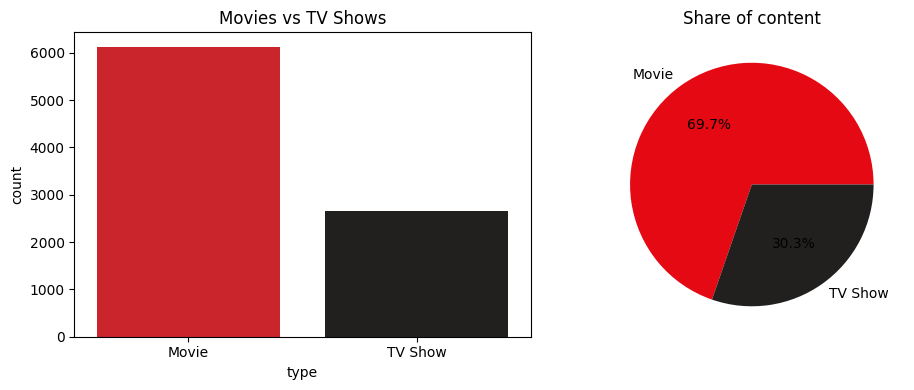

In [10]:
type_counts = df_clean["type"].value_counts()
print(type_counts)
print()
print((type_counts / len(df_clean) * 100).round(1))

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.countplot(x="type", data=df_clean, palette=["#E50914", "#221F1F"])
plt.title("Movies vs TV Shows")

plt.subplot(1, 2, 2)
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", colors=["#E50914", "#221F1F"])
plt.title("Share of content")

plt.tight_layout()
plt.show()

## Step 3: Top countries and categories

country
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64


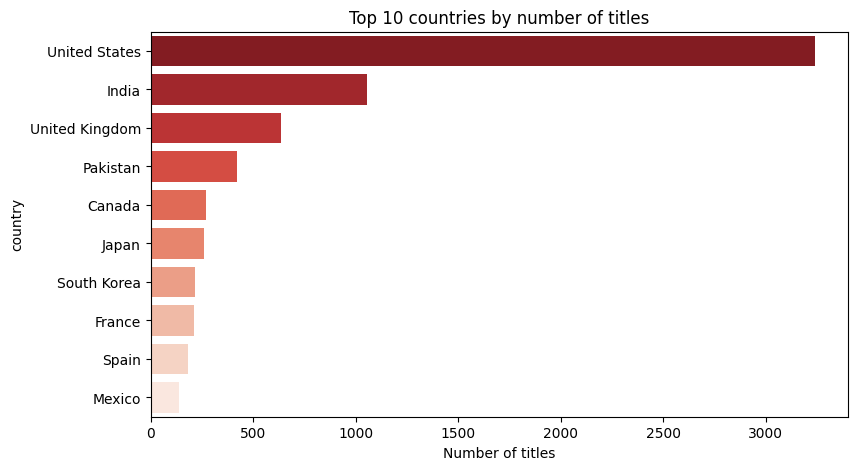

In [11]:
# top countries (not counting Unknown)
known_country = df_clean[df_clean["country"] != "Unknown"]
top_countries = known_country["country"].value_counts().head(10)
print(top_countries)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_countries.values, y=top_countries.index, palette="Reds_r")
plt.title("Top 10 countries by number of titles")
plt.xlabel("Number of titles")
plt.show()

genre_list
International Movies        2752
Dramas                      2424
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


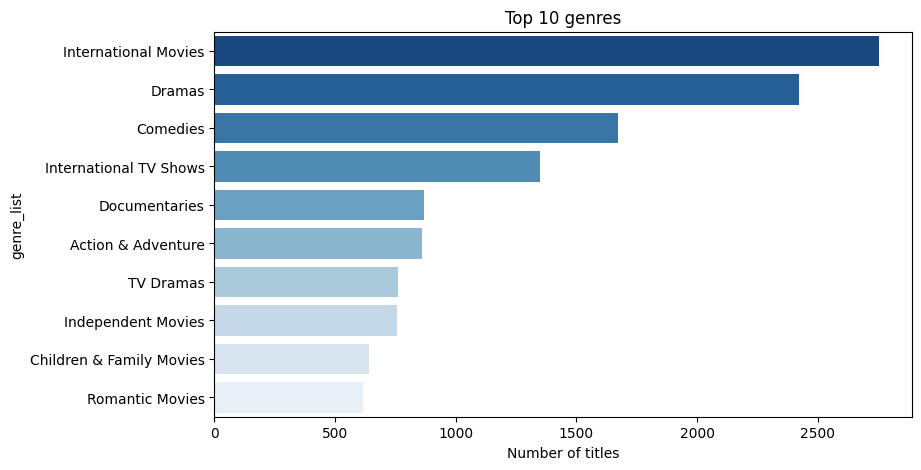

In [12]:
# top genres - one title can have many genres so using explode
genres = df_clean.explode("genre_list")
top_genres = genres["genre_list"].value_counts().head(10)
print(top_genres)

plt.figure(figsize=(9, 5))
sns.barplot(x=top_genres.values, y=top_genres.index, palette="Blues_r")
plt.title("Top 10 genres")
plt.xlabel("Number of titles")
plt.show()

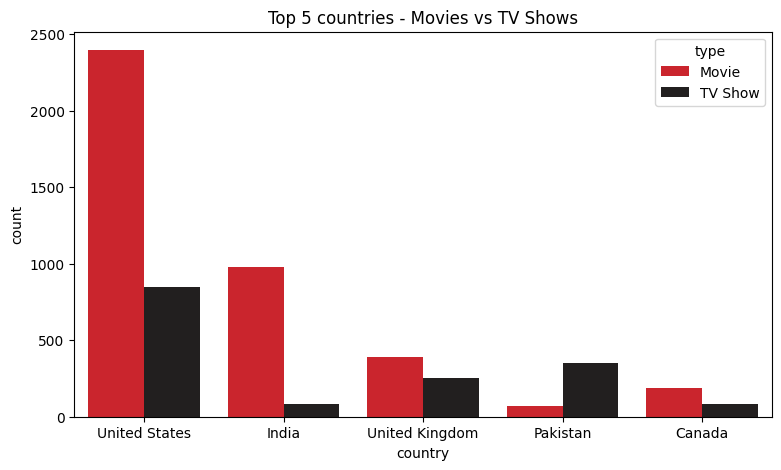

Top 10 directors:
director
Rajiv Chilaka             20
Alastair Fothergill       18
Raúl Campos, Jan Suter    18
Marcus Raboy              16
Suhas Kadav               16
Jay Karas                 14
Cathy Garcia-Molina       13
Jay Chapman               12
Martin Scorsese           12
Youssef Chahine           12
Name: count, dtype: int64


In [13]:
# top countries split by type
top5 = known_country["country"].value_counts().head(5).index
data5 = known_country[known_country["country"].isin(top5)]

plt.figure(figsize=(9, 5))
sns.countplot(x="country", hue="type", data=data5, order=top5, palette=["#E50914", "#221F1F"])
plt.title("Top 5 countries - Movies vs TV Shows")
plt.show()

# top directors (not counting Unknown)
known_dir = df_clean[df_clean["director"] != "Unknown"]
print("Top 10 directors:")
print(known_dir["director"].value_counts().head(10))

## Step 4: Visualizations for key metrics

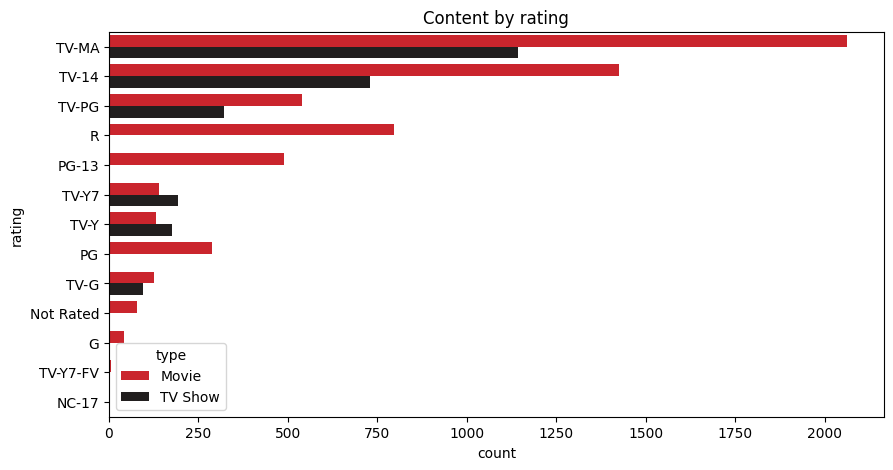

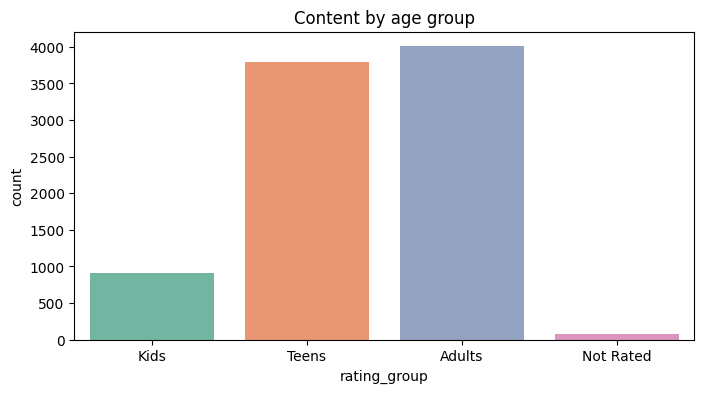

In [14]:
plt.figure(figsize=(10, 5))
sns.countplot(y="rating", hue="type", data=df_clean, order=df_clean["rating"].value_counts().index, palette=["#E50914", "#221F1F"])
plt.title("Content by rating")
plt.show()

plt.figure(figsize=(8, 4))
sns.countplot(x="rating_group", data=df_clean, order=["Kids", "Teens", "Adults", "Not Rated"], palette="Set2")
plt.title("Content by age group")
plt.show()

type        Movie  TV Show
year_added                
2008            1        1
2009            2        0
2010            1        0
2011           13        0
2012            3        0
2013            6        5
2014           19        5
2015           56       26
2016          251      175
2017          836      349
2018         1236      411
2019         1423      591
2020         1284      595
2021          993      505


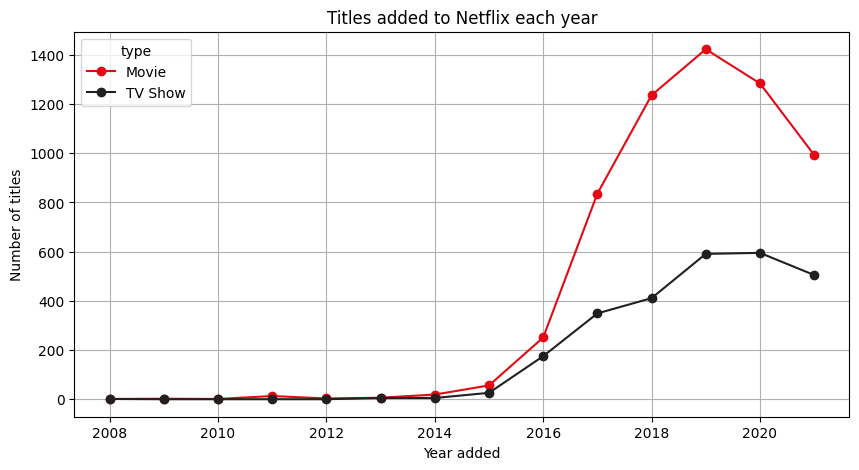

In [15]:
added_per_year = df_clean.groupby(["year_added", "type"]).size().unstack(fill_value=0)
print(added_per_year)

added_per_year.plot(kind="line", marker="o", figsize=(10, 5), color=["#E50914", "#221F1F"])
plt.title("Titles added to Netflix each year")
plt.xlabel("Year added")
plt.ylabel("Number of titles")
plt.grid(True)
plt.show()

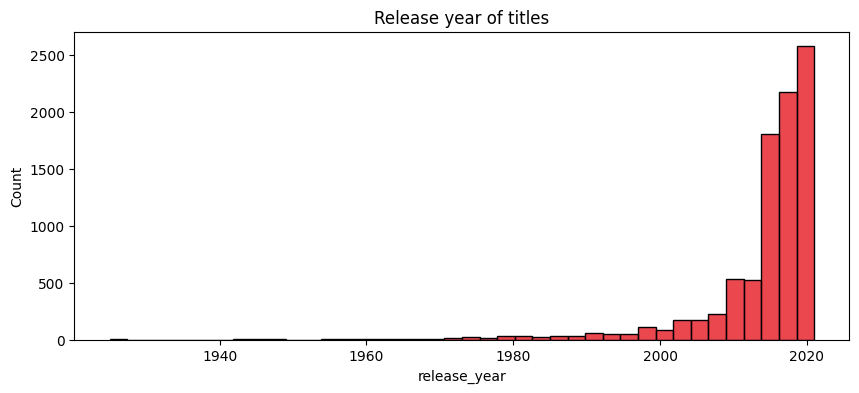

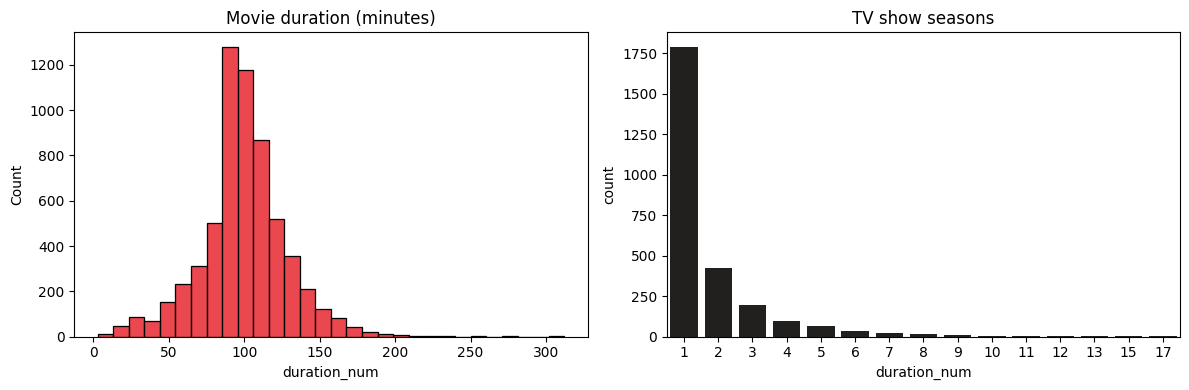

average movie length: 99.6 minutes
TV shows with only 1 season: 67.2 %


In [16]:
plt.figure(figsize=(10, 4))
sns.histplot(df_clean["release_year"], bins=40, color="#E50914")
plt.title("Release year of titles")
plt.show()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
movies = df_clean[df_clean["type"] == "Movie"]
sns.histplot(movies["duration_num"], bins=30, color="#E50914")
plt.title("Movie duration (minutes)")

plt.subplot(1, 2, 2)
shows = df_clean[df_clean["type"] == "TV Show"]
sns.countplot(x="duration_num", data=shows, color="#221F1F")
plt.title("TV show seasons")

plt.tight_layout()
plt.show()

print("average movie length:", round(movies["duration_num"].mean(), 1), "minutes")
print("TV shows with only 1 season:", round((shows["duration_num"] == 1).mean() * 100, 1), "%")

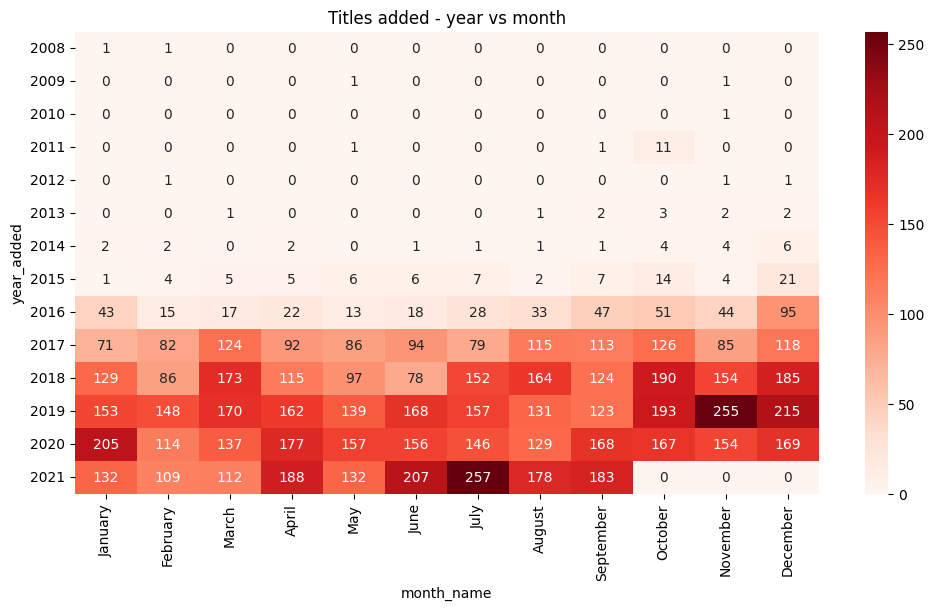

busiest months:
month_name
July         827
December     812
September    769
Name: count, dtype: int64


In [17]:
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
month_table = df_clean.groupby(["year_added", "month_name"]).size().unstack(fill_value=0)
month_table = month_table[month_order]

plt.figure(figsize=(12, 6))
sns.heatmap(month_table, cmap="Reds", annot=True, fmt="d")
plt.title("Titles added - year vs month")
plt.show()

print("busiest months:")
print(df_clean["month_name"].value_counts().head(3))

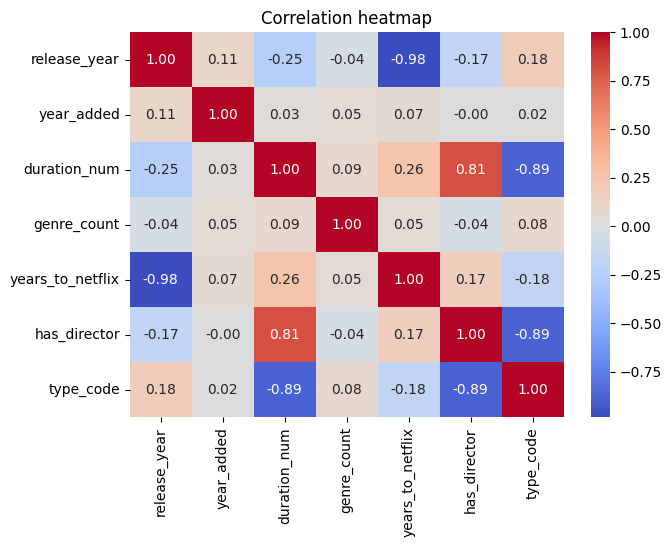

In [18]:
plt.figure(figsize=(7, 5))
sns.heatmap(df_clean[["release_year", "year_added", "duration_num", "genre_count", "years_to_netflix", "has_director", "type_code"]].corr(),
            annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.show()

## Step 5: Summary of findings

In [19]:
print("Total titles:", len(df_clean))
print("Movies:", round((df_clean["type"] == "Movie").mean() * 100, 1), "%   TV Shows:", round((df_clean["type"] == "TV Show").mean() * 100, 1), "%")
print("Top country:", top_countries.index[0], "with", top_countries.iloc[0], "titles")
print("Top genre:", top_genres.index[0], "with", top_genres.iloc[0], "titles")
print("Most common rating:", df_clean["rating"].value_counts().index[0])
print("Year with most titles added:", df_clean["year_added"].value_counts().index[0])
print("Year with most releases:", df_clean["release_year"].value_counts().index[0])
print("Titles with unknown director:", round((df_clean["director"] == "Unknown").mean() * 100, 1), "%")

Total titles: 8787
Movies: 69.7 %   TV Shows: 30.3 %
Top country: United States with 3240 titles
Top genre: International Movies with 2752 titles
Most common rating: TV-MA
Year with most titles added: 2019
Year with most releases: 2018
Titles with unknown director: 29.4 %


**Task 2 - what I found**
- Netflix has more Movies (69.7%) than TV Shows (30.3%).
- United States is far ahead with 3,240 titles (about 37%), then India (1,056), United Kingdom (638) and Pakistan (420).
- Top genres: International Movies (2,752), Dramas (2,424) and Comedies (1,673). For TV, International TV Shows and TV Dramas lead.
- TV-MA is the most common rating, and 45.6% of all content is for adults while only 10.3% is for kids.
- Movies run about 100 minutes on average (99.6) and 67.2% of the TV shows have just 1 season.
- Titles added per year grew a lot from 2016, peaked in 2019 (2,016 titles), and 2021 is lower because the data stops in Sep 2021.
- July, December and September are the busiest months for adding content.
- 29.4% of the titles have no director listed, and this is mostly TV shows.

# Task 3 (Medium) - Recommendation System Analysis
**Goal:** build a simple content-based recommender. If a person likes one title, suggest 5 similar titles.

Idea: make one text for every title (type + genres + country + director + rating group) → TF-IDF → cosine similarity → pick the most similar titles.

## Step 1 and 2: Extract features and clean the text

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

rec_df = df_clean.reset_index(drop=True).copy()

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9 ]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# director "Unknown" and country "Unknown" should not match with each other
rec_df["director_text"] = rec_df["director"].replace("Unknown", "")
rec_df["country_text"] = rec_df["country"].replace("Unknown", "")

rec_df["features"] = (rec_df["type"].astype(str) + " " +
                      rec_df["listed_in"] + " " + rec_df["listed_in"] + " " +
                      rec_df["country_text"] + " " +
                      rec_df["director_text"] + " " +
                      rec_df["rating_group"].astype(str))

rec_df["features"] = rec_df["features"].apply(clean_text)
rec_df[["title", "features"]].head()

,title,features
0,Dick Johnson Is Dead,movie documentaries documentaries united state...
1,Ganglands,tv show crime tv shows international tv shows ...
2,Midnight Mass,tv show tv dramas tv horror tv mysteries tv dr...
3,Confessions of an Invisible Girl,movie children family movies comedies children...
4,Sankofa,movie dramas independent movies international ...


## Step 3: TF-IDF and similarity

In [21]:
tfidf = TfidfVectorizer(stop_words="english")
tfidf_matrix = tfidf.fit_transform(rec_df["features"])
print("tfidf matrix shape:", tfidf_matrix.shape)

# making a lookup of title to row number
title_index = {}
for i in range(len(rec_df)):
    t = rec_df["title"].iloc[i].lower()
    if t not in title_index:
        title_index[t] = i

def recommend(title, n=5):
    key = title.lower().strip()
    if key not in title_index:
        print("title not found:", title)
        return None
    idx = title_index[key]
    scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()
    order = scores.argsort()[::-1]
    order = [i for i in order if i != idx][:n]
    result = rec_df.iloc[order][["title", "type", "country", "rating", "listed_in"]].copy()
    result["similarity"] = scores[order].round(3)
    return result

tfidf matrix shape: (8787, 6545)


## Step 4: Recommendations for selected titles

In [22]:
for name in ["Ganglands", "Midnight Mass", "The Great British Baking Show", "Motu Patlu in Wonderland"]:
    print("If you liked:", name)
    print(rec_df[rec_df["title"] == name][["type", "country", "listed_in"]].iloc[0].to_dict())
    display(recommend(name))
    print()

If you liked: Ganglands
{'type': 'TV Show', 'country': 'France', 'listed_in': 'Crime TV Shows, International TV Shows, TV Action & Adventure'}


,title,type,country,rating,listed_in,similarity
6735,Lupin,TV Show,France,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",0.891
8405,Crime Time,TV Show,France,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",0.891
575,Fatal Destiny,TV Show,Pakistan,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",0.858
8331,Agent Raghav,TV Show,India,TV-14,"Crime TV Shows, International TV Shows, TV Act...",0.857
7969,Smoking,TV Show,Japan,TV-MA,"Crime TV Shows, International TV Shows, TV Act...",0.854



If you liked: Midnight Mass
{'type': 'TV Show', 'country': 'United States', 'listed_in': 'TV Dramas, TV Horror, TV Mysteries'}


,title,type,country,rating,listed_in,similarity
7043,The Haunting of Bly Manor,TV Show,United States,TV-MA,"TV Dramas, TV Horror, TV Mysteries",0.895
6616,Brand New Cherry Flavor,TV Show,United States,TV-MA,"TV Dramas, TV Horror, TV Mysteries",0.895
7073,Ratched,TV Show,United States,TV-MA,"TV Dramas, TV Horror, TV Mysteries",0.895
7907,The Haunting of Hill House,TV Show,United States,TV-MA,"TV Dramas, TV Horror, TV Mysteries",0.895
7959,The Originals,TV Show,United States,TV-14,"TV Dramas, TV Horror, TV Mysteries",0.888



If you liked: The Great British Baking Show
{'type': 'TV Show', 'country': 'United Kingdom', 'listed_in': 'British TV Shows, Reality TV'}


,title,type,country,rating,listed_in,similarity
8714,The Great British Baking Show: Masterclass,TV Show,United Kingdom,TV-PG,"British TV Shows, Reality TV",0.835
8594,Operation Gold Rush,TV Show,United Kingdom,TV-14,"British TV Shows, Reality TV",0.835
6973,The Repair Shop,TV Show,United Kingdom,TV-PG,"British TV Shows, Reality TV",0.835
8697,The Big Catch,TV Show,United Kingdom,TV-PG,"British TV Shows, Reality TV",0.835
7184,21 Again,TV Show,United Kingdom,TV-MA,"British TV Shows, Reality TV",0.826



If you liked: Motu Patlu in Wonderland
{'type': 'Movie', 'country': 'India', 'listed_in': 'Children & Family Movies, Music & Musicals'}


,title,type,country,rating,listed_in,similarity
1066,Motu Patlu Kung Fu Kings 4 The Challenge of Ku...,Movie,India,TV-Y7,"Children & Family Movies, Music & Musicals",1.000
1063,Motu Patlu in Hong Kong: Kung Fu Kings 3,Movie,India,TV-Y7,"Children & Family Movies, Music & Musicals",1.000
7,Motu Patlu in the Game of Zones,Movie,India,TV-Y7,"Children & Family Movies, Comedies, Music & Mu...",0.972
1065,Motu Patlu in the City of Gold,Movie,India,TV-Y7,"Children & Family Movies, Comedies, Music & Mu...",0.972
1068,Motu Patlu the Superheroes – Super Villains fr...,Movie,India,TV-Y7,Children & Family Movies,0.798


## Step 5: Evaluate recommendation quality

There is no user rating data in this file, so I checked quality in a simple way. For 300 random titles I got the top 5 recommendations and checked:
- **Same type** - is the recommended title also a Movie / TV Show like the original?
- **Genre match** - does the recommended title share at least one genre with the original?
- **Same age group** - is the rating group same?

I also compared with 5 random titles as a baseline. Genres are part of the features, so genre match will naturally be high - the baseline shows how much better than random it is.

           Metric  Recommender (%)  Random baseline (%)
0       Same type             99.1                 58.7
1     Genre match             96.5                 24.4
2  Same age group             71.5                 39.3


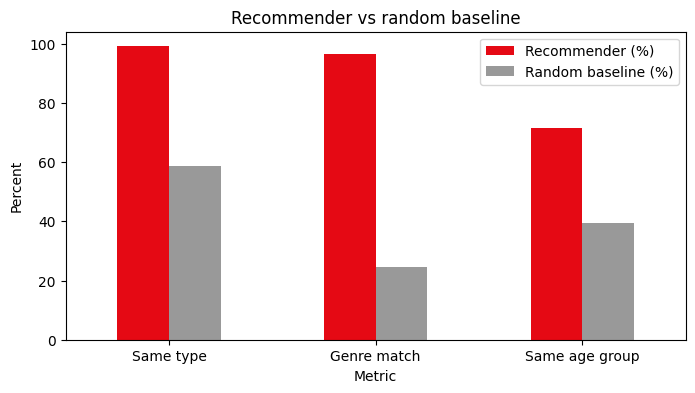

In [23]:
np.random.seed(42)
sample_idx = np.random.choice(len(rec_df), 300, replace=False)

same_type_list = []
genre_match_list = []
same_age_list = []
rand_type_list = []
rand_genre_list = []
rand_age_list = []

for idx in sample_idx:
    scores = cosine_similarity(tfidf_matrix[idx], tfidf_matrix).flatten()
    order = scores.argsort()[::-1]
    top5 = [i for i in order if i != idx][:5]
    rand5 = list(np.random.choice([i for i in range(len(rec_df)) if i != idx], 5, replace=False))

    original_genres = set(rec_df["genre_list"].iloc[idx])
    original_type = rec_df["type"].iloc[idx]
    original_age = rec_df["rating_group"].iloc[idx]

    for group, t_list, g_list, a_list in [(top5, same_type_list, genre_match_list, same_age_list),
                                          (rand5, rand_type_list, rand_genre_list, rand_age_list)]:
        for j in group:
            t_list.append(rec_df["type"].iloc[j] == original_type)
            g_list.append(len(original_genres & set(rec_df["genre_list"].iloc[j])) > 0)
            a_list.append(rec_df["rating_group"].iloc[j] == original_age)

eval_table = pd.DataFrame({
    "Metric": ["Same type", "Genre match", "Same age group"],
    "Recommender (%)": [np.mean(same_type_list) * 100, np.mean(genre_match_list) * 100, np.mean(same_age_list) * 100],
    "Random baseline (%)": [np.mean(rand_type_list) * 100, np.mean(rand_genre_list) * 100, np.mean(rand_age_list) * 100]
}).round(1)
print(eval_table)

eval_table.set_index("Metric").plot(kind="bar", figsize=(8, 4), color=["#E50914", "#999999"])
plt.title("Recommender vs random baseline")
plt.ylabel("Percent")
plt.xticks(rotation=0)
plt.show()

**Task 3 - what I found**
- The recommender gives sensible results, e.g. Ganglands → Lupin and Crime Time (French crime shows), Midnight Mass → The Haunting of Hill House and Bly Manor, Motu Patlu movies → other Motu Patlu movies.
- Out of the 5 recommendations: 99.1% were the same type, 96.5% shared a genre and 71.5% had the same age group. A random pick gave only 58.7%, 24.4% and 39.3%.
- Limits: it only uses tags (genre, country, director, rating), not the story or the cast, and the file has no user ratings, so real "did the user like it" accuracy cannot be measured. Adding a description column would make it better.

# Task 4 (Medium) - Trend Prediction Analysis
**Goal:** look at how many titles were released each year and forecast the next few years.

Release year 2021 is not complete in this data (titles were added only till Sep 2021), so I use 2000 to 2020 for building the models.

## Step 1 and 2: Prepare yearly data and see the trend

         0     1     2     3     4     5     6     7     8     9   ...    11  \
year   2000  2001  2002  2003  2004  2005  2006  2007  2008  2009  ...  2011   
count    37    45    51    59    64    80    96    88   135   152  ...   185   

         12    13    14    15    16    17    18    19    20  
year   2012  2013  2014  2015  2016  2017  2018  2019  2020  
count   236   286   352   555   901  1030  1144  1029   953  

[2 rows x 21 columns]


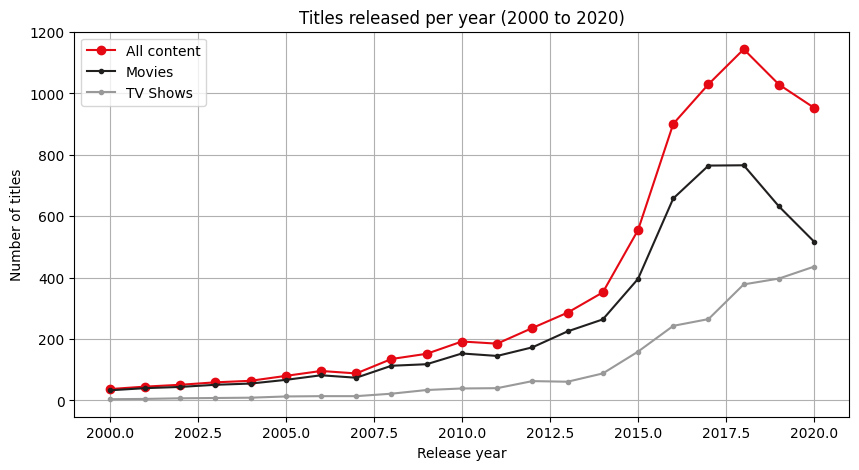

    year  count  growth_%
13  2013    286      21.2
14  2014    352      23.1
15  2015    555      57.7
16  2016    901      62.3
17  2017   1030      14.3
18  2018   1144      11.1
19  2019   1029     -10.1
20  2020    953      -7.4


In [24]:
yearly = df_clean.groupby("release_year").size()
yearly = yearly[(yearly.index >= 2000) & (yearly.index <= 2020)]
yearly_df = yearly.reset_index()
yearly_df.columns = ["year", "count"]
print(yearly_df.T)

type_year = df_clean.groupby(["release_year", "type"]).size().unstack(fill_value=0)
type_year = type_year[(type_year.index >= 2000) & (type_year.index <= 2020)]

plt.figure(figsize=(10, 5))
plt.plot(yearly_df["year"], yearly_df["count"], marker="o", color="#E50914", label="All content")
plt.plot(type_year.index, type_year["Movie"], marker=".", color="#221F1F", label="Movies")
plt.plot(type_year.index, type_year["TV Show"], marker=".", color="#999999", label="TV Shows")
plt.title("Titles released per year (2000 to 2020)")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.legend()
plt.grid(True)
plt.show()

yearly_df["growth_%"] = yearly_df["count"].pct_change() * 100
print(yearly_df[["year", "count", "growth_%"]].round(1).tail(8))

## Step 3: Build forecasting models

I split the years in time order - train on 2000 to 2017 and test on 2018 to 2020 (a random split is wrong for time data). Five models are tried:
- Linear Regression and Polynomial (degree 2) - trend lines
- Holt exponential smoothing
- Moving average of the last 3 years
- Naive - just repeat the last year

The last two are very simple, but they are good to compare against. If a fancy model cannot beat them, it is not useful.

In [25]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import ExponentialSmoothing

train = yearly_df[yearly_df["year"] <= 2017]
test = yearly_df[yearly_df["year"] >= 2018]

x_train = train[["year"]].values
x_test = test[["year"]].values
y_train = train["count"].values
y_test = test["count"].values

test_preds = {}

# model 1 - linear
lin = LinearRegression()
lin.fit(x_train, y_train)
test_preds["Linear Regression"] = lin.predict(x_test)

# model 2 - polynomial degree 2
poly = PolynomialFeatures(degree=2)
poly_model = LinearRegression()
poly_model.fit(poly.fit_transform(x_train), y_train)
test_preds["Polynomial (deg 2)"] = poly_model.predict(poly.transform(x_test))

# model 3 - holt
holt = ExponentialSmoothing(y_train, trend="add", damped_trend=True).fit()
test_preds["Holt Smoothing"] = holt.forecast(len(test))

# model 4 - average of last 3 years
test_preds["Moving Avg (3 yrs)"] = np.repeat(y_train[-3:].mean(), len(test))

# model 5 - naive, last year repeated
test_preds["Naive (last year)"] = np.repeat(y_train[-1], len(test))

results = []
for name in test_preds:
    pred = test_preds[name]
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mape = np.mean(np.abs(y_test - pred) / y_test) * 100
    results.append([name, round(mae, 1), round(rmse, 1), round(mape, 1)])

results_df = pd.DataFrame(results, columns=["Model", "MAE", "RMSE", "MAPE %"])
print(results_df.sort_values("RMSE"))

                Model    MAE   RMSE  MAPE %
4   Naive (last year)   64.0   79.4     6.0
3  Moving Avg (3 yrs)  213.3  227.3    20.0
1  Polynomial (deg 2)  231.5  268.6    23.3
0   Linear Regression  319.7  339.7    30.0
2      Holt Smoothing  351.3  417.7    35.5


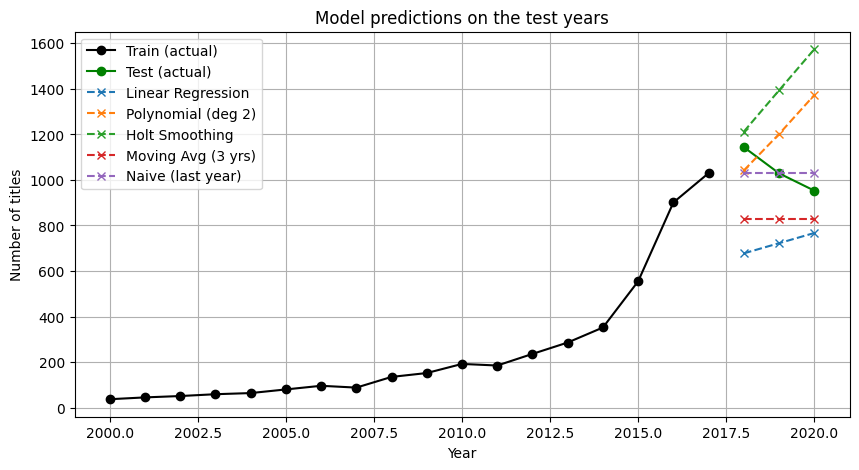

In [26]:
plt.figure(figsize=(10, 5))
plt.plot(train["year"], train["count"], marker="o", color="black", label="Train (actual)")
plt.plot(test["year"], test["count"], marker="o", color="green", label="Test (actual)")
for name in test_preds:
    plt.plot(test["year"], test_preds[name], marker="x", linestyle="--", label=name)
plt.title("Model predictions on the test years")
plt.xlabel("Year")
plt.ylabel("Number of titles")
plt.legend()
plt.grid(True)
plt.show()

## Step 4: Forecast the future

best model on test years: Naive (last year)
   year  Linear Regression  Polynomial (deg 2)  Holt Smoothing  \
0  2021              977.0              1344.0           888.0   
1  2022             1032.0              1499.0           835.0   
2  2023             1088.0              1664.0           794.0   
3  2024             1144.0              1837.0           760.0   
4  2025             1199.0              2018.0           734.0   
5  2026             1255.0              2209.0           712.0   

   Moving Avg (3 yrs)  Naive (last year)  
0              1042.0                953  
1              1042.0                953  
2              1042.0                953  
3              1042.0                953  
4              1042.0                953  
5              1042.0                953  


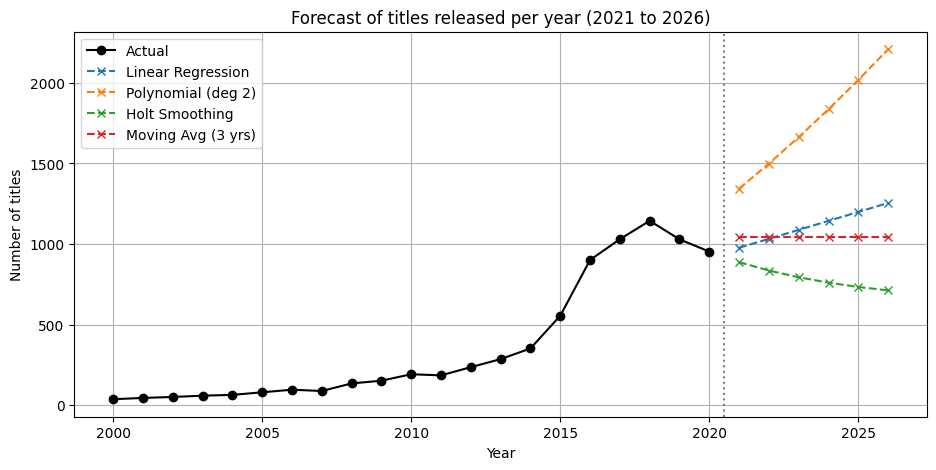

titles with release year 2021 in the data (till Sep 2021 only): 592


In [27]:
best_name = results_df.sort_values("RMSE").iloc[0]["Model"]
print("best model on test years:", best_name)

# training again on all years 2000 to 2020 then forecasting 2021 to 2026
x_all = yearly_df[["year"]].values
y_all = yearly_df["count"].values
future_years = np.array([2021, 2022, 2023, 2024, 2025, 2026])
steps = len(future_years)

lin_all = LinearRegression().fit(x_all, y_all)
lin_future = lin_all.predict(future_years.reshape(-1, 1))

poly_all = PolynomialFeatures(degree=2)
poly_model_all = LinearRegression().fit(poly_all.fit_transform(x_all), y_all)
poly_future = poly_model_all.predict(poly_all.transform(future_years.reshape(-1, 1)))

holt_all = ExponentialSmoothing(y_all, trend="add", damped_trend=True).fit()
holt_future = holt_all.forecast(steps)

ma_future = np.repeat(y_all[-3:].mean(), steps)
naive_future = np.repeat(y_all[-1], steps)

forecast_df = pd.DataFrame({
    "year": future_years,
    "Linear Regression": lin_future.round(0),
    "Polynomial (deg 2)": poly_future.round(0),
    "Holt Smoothing": holt_future.round(0),
    "Moving Avg (3 yrs)": ma_future.round(0),
    "Naive (last year)": naive_future.round(0)
})
print(forecast_df)

plt.figure(figsize=(11, 5))
plt.plot(yearly_df["year"], yearly_df["count"], marker="o", color="black", label="Actual")
plt.plot(future_years, lin_future, marker="x", linestyle="--", label="Linear Regression")
plt.plot(future_years, poly_future, marker="x", linestyle="--", label="Polynomial (deg 2)")
plt.plot(future_years, holt_future, marker="x", linestyle="--", label="Holt Smoothing")
plt.plot(future_years, ma_future, marker="x", linestyle="--", label="Moving Avg (3 yrs)")
plt.axvline(2020.5, color="grey", linestyle=":")
plt.title("Forecast of titles released per year (2021 to 2026)")
plt.xlabel("Year")
plt.ylabel("Number of titles")
plt.legend()
plt.grid(True)
plt.show()

actual_2021 = (df_clean["release_year"] == 2021).sum()
print("titles with release year 2021 in the data (till Sep 2021 only):", actual_2021)

## Step 5: Interpret the results

**Task 4 - what I found**
- Titles released per year grew from 37 in 2000 to a peak of about 1,144 in 2018. After that the number went down (1,029 in 2019 and 953 in 2020).
- Linear and Polynomial models only see the long rising line, so they keep predicting growth. On the test years (2018 to 2020) they were wrong by about 30%.
- The simple "repeat last year" model was the best on the test years (MAE 64, MAPE 6%) and Holt smoothing was the worst, because the growth stopped suddenly after 2018.
- So the honest forecast is that yearly releases will stay roughly flat at about 950 to 1,050 titles per year. Linear Regression says 1,255 by 2026, Polynomial says 2,209 and Holt says 712, but I trust them less.
- Limits: only 21 yearly points, and 2021 is not complete in the data (592 titles till Sep 2021). Also this is the release year of titles already on Netflix, so very old titles are only there if Netflix kept them.

# Task 5 (Advanced) - Machine Learning Classification Model
**Goal:** predict if a title is a **Movie** or a **TV Show** using the other features.

Important: `duration` ("90 min" / "2 Seasons") and `listed_in` (genres like "TV Dramas") directly tell the answer, so I am **not** using them as features. Using them would give 100% accuracy but the model would be useless (this is called data leakage).

## Step 1: Select and prepare features

In [28]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

ml_df = df_clean.copy()

# keeping only top 10 countries, rest as Other
top10 = ml_df["country"].value_counts().head(10).index
ml_df["country_small"] = ml_df["country"].where(ml_df["country"].isin(top10), "Other")

features = ["release_year", "year_added", "month_added", "years_to_netflix", "genre_count", "has_director", "rating", "country_small"]
X = ml_df[features].copy()
X["rating"] = X["rating"].astype(str)
X = pd.get_dummies(X, columns=["rating", "country_small"], drop_first=True)
y = ml_df["type_code"]

print("features used:", X.shape[1])
print("target counts:")
print(y.value_counts())

features used: 28
target counts:
type_code
0    6124
1    2663
Name: count, dtype: int64


## Step 2: Train and test split

In [29]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("train:", X_train.shape, " test:", X_test.shape)

# scaling is needed for logistic regression and knn
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

baseline = y_test.value_counts(normalize=True).max()
print("baseline accuracy (always guess Movie):", round(baseline * 100, 1), "%")

train: (7029, 28)  test: (1758, 28)
baseline accuracy (always guess Movie): 69.7 %


## Step 3: Train classification models

In [30]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7)
}

predictions = {}
for name in models:
    if name in ["Logistic Regression", "KNN"]:
        models[name].fit(X_train_scaled, y_train)
        predictions[name] = models[name].predict(X_test_scaled)
    else:
        models[name].fit(X_train, y_train)
        predictions[name] = models[name].predict(X_test)
    print(name, "trained")

Logistic Regression trained
Decision Tree trained
Random Forest trained
KNN trained


## Step 4: Evaluate performance

In [31]:
score_list = []
for name in predictions:
    p = predictions[name]
    score_list.append([name,
                       round(accuracy_score(y_test, p), 3),
                       round(precision_score(y_test, p), 3),
                       round(recall_score(y_test, p), 3),
                       round(f1_score(y_test, p), 3)])

score_df = pd.DataFrame(score_list, columns=["Model", "Accuracy", "Precision (TV)", "Recall (TV)", "F1 (TV)"])
print(score_df)

                 Model  Accuracy  Precision (TV)  Recall (TV)  F1 (TV)
0  Logistic Regression     0.948           0.933        0.893    0.913
1        Decision Tree     0.944           0.926        0.887    0.906
2        Random Forest     0.945           0.924        0.893    0.908
3                  KNN     0.939           0.928        0.865    0.895


## Step 5: Compare model accuracy

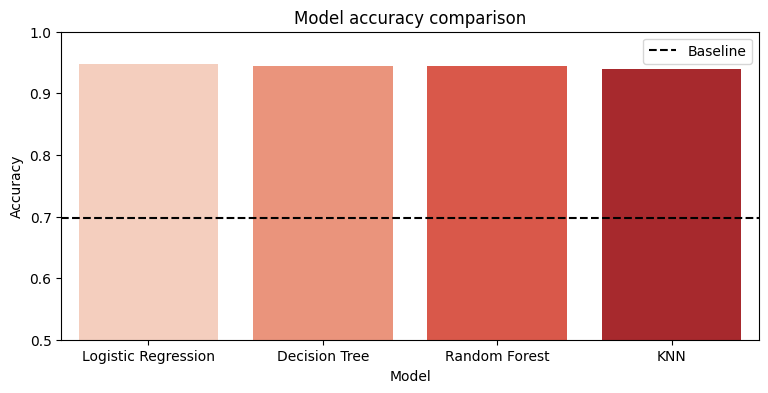

best model (by F1 for TV Shows): Logistic Regression

              precision    recall  f1-score   support

       Movie       0.95      0.97      0.96      1225
     TV Show       0.93      0.89      0.91       533

    accuracy                           0.95      1758
   macro avg       0.94      0.93      0.94      1758
weighted avg       0.95      0.95      0.95      1758



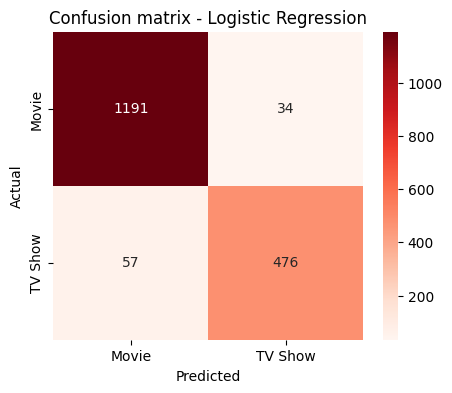

In [32]:
plt.figure(figsize=(9, 4))
sns.barplot(x="Model", y="Accuracy", data=score_df, palette="Reds")
plt.axhline(baseline, color="black", linestyle="--", label="Baseline")
plt.ylim(0.5, 1)
plt.title("Model accuracy comparison")
plt.legend()
plt.show()

best_model_name = score_df.sort_values("F1 (TV)", ascending=False).iloc[0]["Model"]
print("best model (by F1 for TV Shows):", best_model_name)
print()
print(classification_report(y_test, predictions[best_model_name], target_names=["Movie", "TV Show"]))

cm = confusion_matrix(y_test, predictions[best_model_name])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=["Movie", "TV Show"], yticklabels=["Movie", "TV Show"])
plt.title("Confusion matrix - " + best_model_name)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

random forest 5 fold scores: [0.951 0.951 0.943 0.94  0.945]
average: 0.946


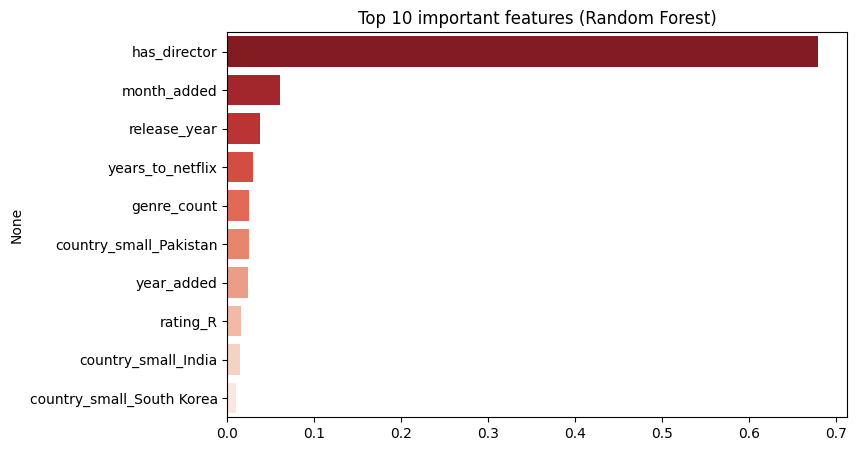

has_director                 0.679
month_added                  0.060
release_year                 0.037
years_to_netflix             0.029
genre_count                  0.025
country_small_Pakistan       0.025
year_added                   0.024
rating_R                     0.016
country_small_India          0.015
country_small_South Korea    0.010
dtype: float64


In [33]:
# cross validation for random forest to check the score is stable
# the csv rows are not in random order, so shuffle is on
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=42), X, y, cv=cv)
print("random forest 5 fold scores:", cv_scores.round(3))
print("average:", round(cv_scores.mean(), 3))

# which features matter
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(8, 5))
sns.barplot(x=importance.values, y=importance.index, palette="Reds_r")
plt.title("Top 10 important features (Random Forest)")
plt.show()
print(importance.round(3))

**Task 5 - what I found**
- All 4 models got about 94 to 95% accuracy, well above the 69.7% baseline of always guessing Movie. Logistic Regression was slightly best (94.8% accuracy, F1 of 0.913 for TV Shows).
- 5-fold cross validation on Random Forest gave 94.6% on average, so the score is stable and not luck.
- The most important feature by far is `has_director` (about 68% of the importance) because most TV shows have no director listed. Month added and release year come next.
- The model is weaker on TV shows (recall 89%) than on movies (97%) because there are fewer TV shows to learn from.
- I removed `duration` and genres from the features since they directly give away the answer. That is why the accuracy is 95% and not 100%.

# Task 6 (Advanced) - Data Science Business Insights Dashboard
**Goal:** one end-to-end project joining analysis, machine learning and business insights, shown with interactive Plotly charts (hover, zoom and click on legend all work).

## Step 1: Complete data analysis - key numbers

In [34]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

total_titles = len(df_clean)
movie_pct = round((df_clean["type"] == "Movie").mean() * 100, 1)
tv_pct = round(100 - movie_pct, 1)
num_countries = known_country["country"].nunique()
latest_year_titles = (df_clean["year_added"] == df_clean["year_added"].max()).sum()
kids_pct = round((df_clean["rating_group"] == "Kids").mean() * 100, 1)
adult_pct = round((df_clean["rating_group"] == "Adults").mean() * 100, 1)

kpi = pd.DataFrame({
    "Metric": ["Total titles", "Movies %", "TV Shows %", "Countries", "Adult content %", "Kids content %"],
    "Value": [total_titles, movie_pct, tv_pct, num_countries, adult_pct, kids_pct]
})
kpi

,Metric,Value
0,Total titles,8787.0
1,Movies %,69.7
2,TV Shows %,30.3
3,Countries,85.0
4,Adult content %,45.6
5,Kids content %,10.3


## Step 2: Predictive models (from Task 4 and Task 5)

In [35]:
print("Classification model results (Movie vs TV Show):")
print(score_df)
print()
print("Forecast of titles released per year:")
print(forecast_df)

Classification model results (Movie vs TV Show):
                 Model  Accuracy  Precision (TV)  Recall (TV)  F1 (TV)
0  Logistic Regression     0.948           0.933        0.893    0.913
1        Decision Tree     0.944           0.926        0.887    0.906
2        Random Forest     0.945           0.924        0.893    0.908
3                  KNN     0.939           0.928        0.865    0.895

Forecast of titles released per year:
   year  Linear Regression  Polynomial (deg 2)  Holt Smoothing  \
0  2021              977.0              1344.0           888.0   
1  2022             1032.0              1499.0           835.0   
2  2023             1088.0              1664.0           794.0   
3  2024             1144.0              1837.0           760.0   
4  2025             1199.0              2018.0           734.0   
5  2026             1255.0              2209.0           712.0   

   Moving Avg (3 yrs)  Naive (last year)  
0              1042.0                953  
1       

## Step 3: Interactive visualizations

In [36]:
# chart 1 - content type
fig1 = px.pie(df_clean, names="type", title="Movies vs TV Shows", color="type",
              color_discrete_map={"Movie": "#E50914", "TV Show": "#221F1F"}, hole=0.4)
fig1.show()

In [37]:
# chart 2 - added per year
added_year = df_clean.groupby(["year_added", "type"]).size().reset_index(name="titles")
fig2 = px.line(added_year, x="year_added", y="titles", color="type", markers=True,
               title="Titles added to Netflix per year",
               color_discrete_map={"Movie": "#E50914", "TV Show": "#221F1F"})
fig2.show()

In [38]:
# chart 3 - top countries with a dropdown to filter the type
def top_country_counts(type_name):
    if type_name == "All":
        d = known_country
    else:
        d = known_country[known_country["type"] == type_name]
    c = d["country"].value_counts().head(10)
    return c

fig3 = go.Figure()
names = ["All", "Movie", "TV Show"]
for i in range(len(names)):
    c = top_country_counts(names[i])
    fig3.add_trace(go.Bar(x=c.index, y=c.values, name=names[i], marker_color="#E50914", visible=(i == 0)))

buttons = []
for i in range(len(names)):
    visible_list = [False, False, False]
    visible_list[i] = True
    buttons.append(dict(label=names[i], method="update", args=[{"visible": visible_list}]))

fig3.update_layout(title="Top 10 countries (use the dropdown to filter type)",
                   updatemenus=[dict(buttons=buttons, x=0.0, y=1.15)],
                   xaxis_title="Country", yaxis_title="Titles")
fig3.show()

In [39]:
# chart 4 - genres treemap and rating chart
genre_counts = genres["genre_list"].value_counts().head(15).reset_index()
genre_counts.columns = ["genre", "titles"]
fig4 = px.treemap(genre_counts, path=["genre"], values="titles", title="Top 15 genres",
                  color="titles", color_continuous_scale="Reds")
fig4.show()

rating_type = df_clean.groupby(["rating", "type"]).size().reset_index(name="titles")
fig5 = px.bar(rating_type, x="rating", y="titles", color="type", barmode="group",
              title="Content by rating", color_discrete_map={"Movie": "#E50914", "TV Show": "#221F1F"})
fig5.show()

In [40]:
# chart 5 - heatmap of year vs month
fig6 = px.imshow(month_table, aspect="auto", color_continuous_scale="Reds",
                 title="Titles added - year vs month")
fig6.show()

# chart 6 - movie duration
fig7 = px.histogram(movies, x="duration_num", nbins=40, title="Movie duration (minutes)",
                    color_discrete_sequence=["#E50914"])
fig7.show()

In [41]:
# chart 7 - forecast
fig8 = go.Figure()
fig8.add_trace(go.Scatter(x=yearly_df["year"], y=yearly_df["count"], mode="lines+markers", name="Actual", line=dict(color="black")))
fig8.add_trace(go.Scatter(x=future_years, y=lin_future, mode="lines+markers", name="Linear Regression", line=dict(dash="dash")))
fig8.add_trace(go.Scatter(x=future_years, y=poly_future, mode="lines+markers", name="Polynomial (deg 2)", line=dict(dash="dash")))
fig8.add_trace(go.Scatter(x=future_years, y=holt_future, mode="lines+markers", name="Holt Smoothing", line=dict(dash="dash")))
fig8.add_trace(go.Scatter(x=future_years, y=ma_future, mode="lines+markers", name="Moving Avg (3 yrs)", line=dict(dash="dash")))
fig8.update_layout(title="Forecast - titles released per year", xaxis_title="Year", yaxis_title="Titles")
fig8.show()

# chart 8 - model comparison
fig9 = px.bar(score_df, x="Model", y="Accuracy", text="Accuracy", title="Classification model accuracy",
              color_discrete_sequence=["#E50914"])
fig9.add_hline(y=baseline, line_dash="dash", annotation_text="baseline")
fig9.update_yaxes(range=[0.5, 1])
fig9.show()

In [42]:
# one combined dashboard page and saving it as html
dash = make_subplots(rows=2, cols=2,
                     specs=[[{"type": "domain"}, {"type": "xy"}], [{"type": "xy"}, {"type": "xy"}]],
                     subplot_titles=("Movies vs TV Shows", "Titles added per year", "Top 10 countries", "Ratings"))

dash.add_trace(go.Pie(labels=type_counts.index, values=type_counts.values, hole=0.4,
                      marker=dict(colors=["#E50914", "#221F1F"])), row=1, col=1)

for t, color in [("Movie", "#E50914"), ("TV Show", "#221F1F")]:
    d = added_year[added_year["type"] == t]
    dash.add_trace(go.Scatter(x=d["year_added"], y=d["titles"], mode="lines+markers", name=t, line=dict(color=color)), row=1, col=2)

dash.add_trace(go.Bar(x=top_countries.index, y=top_countries.values, marker_color="#E50914", showlegend=False), row=2, col=1)

rating_counts = df_clean["rating"].value_counts()
dash.add_trace(go.Bar(x=rating_counts.index, y=rating_counts.values, marker_color="#221F1F", showlegend=False), row=2, col=2)

dash.update_layout(height=750, title_text="Netflix Business Insights Dashboard")
dash.show()

dash.write_html("netflix_dashboard.html")
print("dashboard saved as netflix_dashboard.html")

dashboard saved as netflix_dashboard.html


## Step 4: Business recommendations

1. **Grow TV shows.** Only 30.3% of the catalog is TV, and 67.2% of the shows have 1 season. Renewing the popular shows for more seasons can keep viewers subscribed for longer.
2. **Invest in India and other fast regions.** India (1,056 titles) is the second biggest, and countries like South Korea, Japan and Spain already have good counts. Local content can bring new subscribers there.
3. **Kids content is a gap.** Only 10.3% of titles are kids rated while 45.6% are adult rated. A bigger family catalog could win whole households.
4. **Do not expect the old growth.** Releases have been flat or falling since 2018, so the plan should focus on quality and keeping the best titles instead of just adding more titles.
5. **Plan launches around busy months.** July, December and September have the most additions. Big releases in the quiet months can get less competition for attention.
6. **Use the recommender for "more like this".** Showing similar titles by genre, country and rating works well (96.5% genre match). Adding descriptions and real viewing data would improve it more.
7. **Fix the data.** 29.4% of directors and 3.3% of countries are missing. Better metadata makes both recommendations and analysis stronger.

## Step 5: Final report

### Project: Netflix Content Analysis - Data Science Business Insights

**Objective:** clean, explore, model and present the Netflix titles dataset (8,790 raw rows, 8,787 after cleaning) to give business insights.

**Work done**
| Task | What was done | Key result |
|---|---|---|
| 1. Cleaning | Hidden missing values ("Not Given") fixed, 3 duplicates removed, dates and duration split, genres and age groups made | Clean file with 22 columns and no nulls |
| 2. EDA | 12+ charts on type, country, genre, rating, year and month | 69.7% movies, US is top country, 45.6% adult content |
| 3. Recommender | TF-IDF + cosine similarity on type, genre, country, director, rating | 96.5% genre match vs 24.4% random |
| 4. Trend prediction | 5 forecasting models on yearly releases | Releases peaked in 2018 and are now flat, naive model best |
| 5. Classification | 4 models for Movie vs TV Show without leaky columns | About 94.8% accuracy vs 69.7% baseline |
| 6. Dashboard | Interactive Plotly charts and a saved HTML dashboard | Business recommendations above |

**Main conclusion:** the Netflix catalog is movie heavy, US dominated and adult focused, and its yearly release growth stopped after 2018. The best chances are more TV seasons, regional content and family content.

**Tools used:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Statsmodels, Plotly, Google Colab.

**Files made:** `netflix_clean.csv` and `netflix_dashboard.html`.

---
**Akshat Kesharwani** | Data Analyst & Data Scientist (Fresher)
Portfolio: https://akshatkesharwani-info.github.io/
GitHub: https://github.com/akshatkesharwani-info